# 01 — Sản xuất lúa Việt Nam theo các publication NSO

National quantity trong V06.12; reported yield V06.14 và regional observations V06.15 được giữ riêng.

Environment: Windows host, Python 3.10–3.13; `pip install -r requirements/analytics.txt`.
Docker `tlcn-local` đã healthy, Windows available >=2 GiB, WSL >=3 GiB, không active writer/DagRun.
Không start Spark. Mỗi notebook chạy độc lập, theo thứ tự cells. Query names/typed filters hiển thị
trong retrieval cells; kết quả là full scoped results/aggregates, **không phải 20-row sample consumer**.
Source-scoped identities không phải official crosswalk. Không forward-fill/interpolate.

Chạy `python scripts/run_eda_notebooks.py --notebook <filename>` từ repo root để execute và cập nhật
Markdown diễn giải bằng đúng measured evidence. Kết quả Markdown ghi batch cố định bên trên;
publication đổi sẽ fail closed. Không dùng outputs cũ như live query cache.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/gold/consumer.py').exists())
sys.path.insert(0, str(ROOT/'src'))  # repository bootstrap, no credentials
import pandas as pd
import numpy as np
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from analytics.client import EDAClient
from analytics.methods import calendar_yoy, endpoint_change, monthly_calendar
from analytics.notebook import inspect_frame, label, resolve, annual_plot, save_evidence
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
client = EDAClient()
findings = []
inventory = client.query('publication')
EXPECTED_BATCH = 'ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235'
assert client.batch == EXPECTED_BATCH, 'Publication changed: review scope before reproducing EDA'
display(inventory)
print('Published batch:', client.batch, '| No query cache | Windows/WSL/writer gates checked per request')

,table,rows,uuid,snapshot_id
0,dim_date,2038,0d029553-197b-4e46-8d62-17f21334a11b,7665947661409225898
1,dim_month,800,4f262a83-5e36-4d9e-b7e0-18f91b46327f,8295574410069434036
2,dim_observation_type,34,8adc0a9f-498e-4503-aa05-f95ae5a358ed,1046146616745412073
3,dim_price_series,1042,fa39bf1e-bbf1-4b50-8129-de1d4f37413b,2896601742107309180
4,dim_source_geography,987,ce487b86-5541-44de-a006-365dfbcc29f2,8664595598201008097
5,dim_source_product,295,4ce4f42f-e876-4870-8b2a-0312c460d673,8514812747103222137
6,dim_source_system,9,3c9fdb0f-127a-45f4-8f5b-31c7d1d5c0c1,5212267582300439758
7,dim_year,67,032861f7-4c4e-4ac4-9a10-274670b1d694,3316235776078407392
8,fact_fao_price_annual,9993,3218dd14-0793-4c1d-941c-31ba5e1aaea8,6561274137596983252
9,fact_fao_production_observation,22738,f97e800f-ebe6-416c-918a-a148ec0388b4,4557995850181557281


Published batch: ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235 | No query cache | Windows/WSL/writer gates checked per request


## Câu hỏi 1 — Sản lượng và diện tích annual trong cùng V06.12 thay đổi ra sao?

In [2]:
nso=client.query('nso_observations',source_table='V06.12.csv',start_year=1990,end_year=2024,level='national')
yield_reported=client.query('nso_observations',source_table='V06.14.csv',start_year=1995,end_year=2024,level='national')

In [3]:
display(nso.shape,inspect_frame(nso),nso.head(),yield_reported.shape)

(560, 17)

,dtype,nulls
observation_key,object,0
year_key,int64,0
geography_key,object,0
source_table,object,0
source_geography_key,object,0
measure,object,0
season,object,0
statistic_kind,object,0
value,object,0
unit,object,0


,observation_key,year_key,geography_key,source_table,source_geography_key,measure,season,statistic_kind,value,unit,release_status,quality_status,review_reason,diagnostic_evidence_json,dq_warnings_json,source_labels_json,source_level
0,a2879ca2cef4df1a6d9cb20cbbd628ca0bb6d8d3f18d28...,1999,04e5d1d96ff687156cbce00faf3d86fc30ad0c3e6d1663...,V06.12.csv,__national_table_scope__,area,main_season,quantity,2423500.00000000,hectare,unconfirmed,NORMALIZED,None,[],[],[],national
1,1ad32e6ac092e9b08bf5efcd77762ffeca93409d7f97b3...,1999,04e5d1d96ff687156cbce00faf3d86fc30ad0c3e6d1663...,V06.12.csv,__national_table_scope__,area,summer_autumn,development_index,109.40000000,percent,unconfirmed,NORMALIZED,None,[],[],[],national
2,ede9fcebc99da81bfeacac3c8f01b2c41f33291828a294...,1999,04e5d1d96ff687156cbce00faf3d86fc30ad0c3e6d1663...,V06.12.csv,__national_table_scope__,area,winter_spring,quantity,2888900.00000000,hectare,unconfirmed,NORMALIZED,None,[],[],[],national
3,9ace51a73cc8bcf7d82b425861e976a05fa1eb0ed51682...,1999,04e5d1d96ff687156cbce00faf3d86fc30ad0c3e6d1663...,V06.12.csv,__national_table_scope__,production,annual,quantity,31393800.00000000,tonne,unconfirmed,NORMALIZED,None,[],[],[],national
4,4c8a0a4ee7b5fda12e764f13fbc3082dfe4c93e9ae825d...,1999,04e5d1d96ff687156cbce00faf3d86fc30ad0c3e6d1663...,V06.12.csv,__national_table_scope__,production,main_season,quantity,8532500.00000000,tonne,unconfirmed,NORMALIZED,None,[],[],[],national


(30, 17)

In [4]:
bk=['source_table','geography_key','year_key','measure','season','statistic_kind']
assert not nso.duplicated(bk).any()
quantity=nso[nso.statistic_kind.eq('quantity')].copy()
quantity['value']=pd.to_numeric(quantity.value)
annual=quantity[quantity.season.eq('annual')].copy()
assert annual.geography_key.nunique()==1
assert set(annual.unit)=={'tonne','hectare'}
production=annual[annual.measure.eq('production')].copy()
area=annual[annual.measure.eq('area')].copy()

In [5]:
annual_stats=pd.DataFrame([dict(measure=m,**endpoint_change(df)) for m,df in [('production_t',production),('area_ha',area)]])
display(annual_stats)

,measure,first_year,last_year,first_value,last_value,change_pct,cagr_pct,numeric_periods,calendar_span
0,production_t,1990,2024,19225100.0,43451600.0,126.014949,2.427317,35,35
1,area_ha,1990,2024,6042800.0,7127100.0,17.943668,0.486583,35,35


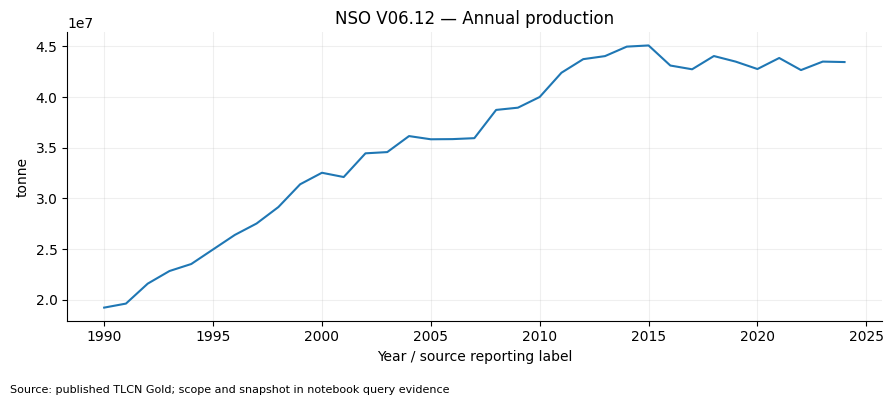

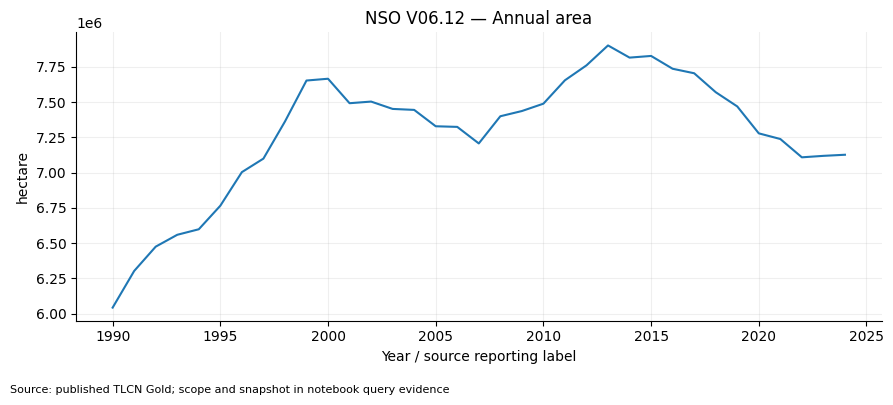

In [6]:
annual_plot(production,'value','NSO V06.12 — Annual production','tonne')
annual_plot(area,'value','NSO V06.12 — Annual area','hectare')

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** Hai chuỗi cùng publication, national scope và annual quantity. Không cộng với regional/provincial hoặc seasonal rows.

In [7]:
for row in annual_stats.to_dict(orient='records'):
    findings.append(dict(id='VN01' if row['measure']=='production_t' else 'VN02',title='Thay đổi annual '+row['measure'],
      observation=f"V06.12: {row['first_value']:,.2f} năm {row['first_year']} → {row['last_value']:,.2f} năm {row['last_year']} ({row['change_pct']:+.2f}%).",
      scope='NSO V06.12.csv, national, annual, quantity; unit in metric',interpretation='So sánh endpoints trong đúng publication; không suy causal attribution hoặc release vintage.',query='nso_observations',cell='Câu hỏi 1',numbers=row))
peak_year=int(production.loc[production.value.idxmax(),'year_key'])
post_production=endpoint_change(production[production.year_key>=peak_year])
post_area=endpoint_change(area[area.year_key>=peak_year])
assert post_production['first_year']==post_area['first_year']==peak_year
display(pd.DataFrame([dict(metric='production_t',**post_production),dict(metric='area_ha',**post_area)]))
findings.append(dict(id='VN05',title='Xu hướng dài hạn che giai đoạn sau observed peak',
 observation=f"Annual production đạt observed peak {post_production['first_value']:,.2f} tonnes năm {peak_year}; tới {post_production['last_year']} còn {post_production['last_value']:,.2f} tonnes ({post_production['change_pct']:+.2f}%). Diện tích cùng interval thay đổi {post_area['change_pct']:+.2f}%.",
 scope='NSO V06.12.csv, national annual quantity; peak selected from observed 1990–2024 series',
 interpretation='Descriptive peak-to-latest comparison; không phải formal structural-break test hoặc chứng minh area gây thay đổi production.',
 query='nso_observations',cell='Câu hỏi 1',numbers=dict(production=post_production,area=post_area)))

,metric,first_year,last_year,first_value,last_value,change_pct,cagr_pct,numeric_periods,calendar_span
0,production_t,2015,2024,45091000.0,43451600.0,-3.635759,-0.410654,10,10
1,area_ha,2015,2024,7828000.0,7127100.0,-8.953756,-1.036839,10,10


## Câu hỏi 2 — YoY và association giữa sản lượng/diện tích?

In [8]:
growth=calendar_yoy(production,[])
paired=production[['year_key','value']].rename(columns={'value':'production_t'}).merge(area[['year_key','value']].rename(columns={'value':'area_ha'}),on='year_key',validate='one_to_one')
paired['computed_yield_kg_ha']=1000*paired.production_t/paired.area_ha.where(paired.area_ha>0)
indexed=paired.set_index('year_key')[['production_t','area_ha','computed_yield_kg_ha']]
indexed=indexed/indexed.iloc[0]*100
display(growth[['year_key','value','previous_value','yoy_pct']],paired.head())

,year_key,value,previous_value,yoy_pct
0,1999,31393800.0,29145500.0,7.714055
1,2003,34568800.0,34447200.0,0.353004
2,2004,36148900.0,34568800.0,4.570885
3,2009,38950200.0,38729800.0,0.569071
4,2015,45091000.0,44974600.0,0.258813
5,2018,44046000.0,42738900.0,3.058338
6,2019,43495400.0,44046000.0,-1.250057
7,2021,43852600.0,42764800.0,2.543681
8,2010,40005600.0,38950200.0,2.709614
9,2016,43109000.0,45091000.0,-4.395556


,year_key,production_t,area_ha,computed_yield_kg_ha
0,1999,31393800.0,7653600.0,4101.834431
1,2003,34568800.0,7452200.0,4638.737554
2,2004,36148900.0,7445300.0,4855.264395
3,2009,38950200.0,7437200.0,5237.212930
4,2015,45091000.0,7828000.0,5760.219724


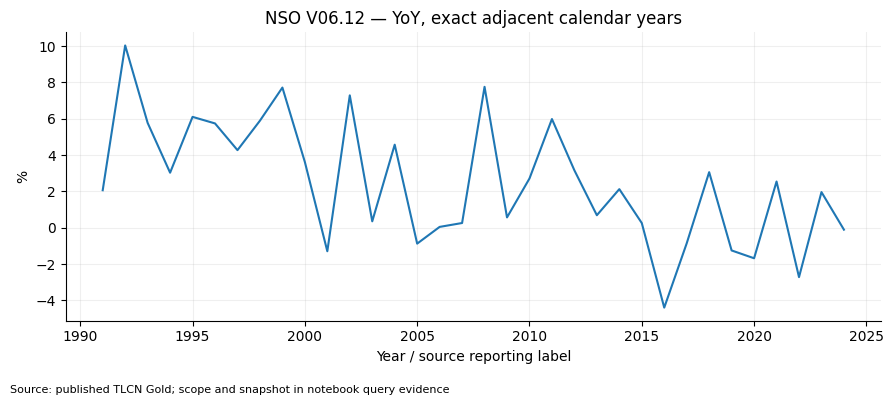

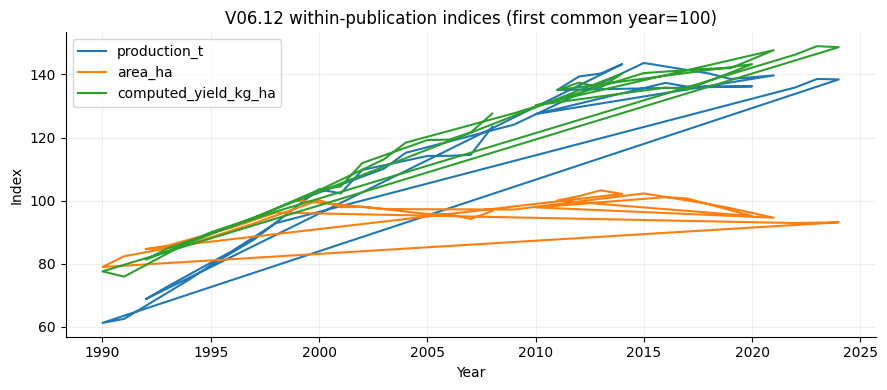

In [9]:
annual_plot(growth,'yoy_pct','NSO V06.12 — YoY, exact adjacent calendar years','%')
ax=indexed.plot(figsize=(9,4),title='V06.12 within-publication indices (first common year=100)',ylabel='Index',xlabel='Year');ax.grid(alpha=.2);plt.tight_layout();plt.show();plt.close()

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** Computed yield là ratio trong cùng V06.12, không đổi thành reported yield. Index co-movement chỉ gợi association, không causal mechanism.

## Câu hỏi 3 — Reported yield và seasonal patterns?

In [10]:
yr=yield_reported[(yield_reported.measure=='yield')&(yield_reported.season=='annual')&(yield_reported.statistic_kind=='quantity')].copy()
yr['value']=pd.to_numeric(yr.value);assert yr.unit.eq('kg/hectare').all()
seasons=quantity[(quantity.measure=='production')&(quantity.season!='annual')].copy()
season_stats=pd.DataFrame([dict(season=s,**endpoint_change(df)) for s,df in seasons.groupby('season')])
display(inspect_frame(yr),season_stats,nso.groupby('release_status').size())

,dtype,nulls
observation_key,object,0
year_key,int64,0
geography_key,object,0
source_table,object,0
source_geography_key,object,0
measure,object,0
season,object,0
statistic_kind,object,0
value,float64,0
unit,object,0


,season,first_year,last_year,first_value,last_value,change_pct,cagr_pct,numeric_periods,calendar_span
0,main_season,1990,2024,7269000.0,7759200.0,6.743706,0.192127,35,35
1,summer_autumn,1990,2024,4090500.0,15353000.0,275.333089,3.966785,35,35
2,winter_spring,1990,2024,7865600.0,20333900.0,158.516833,2.832886,35,35


release_status
provisional     16
unconfirmed    544
dtype: int64

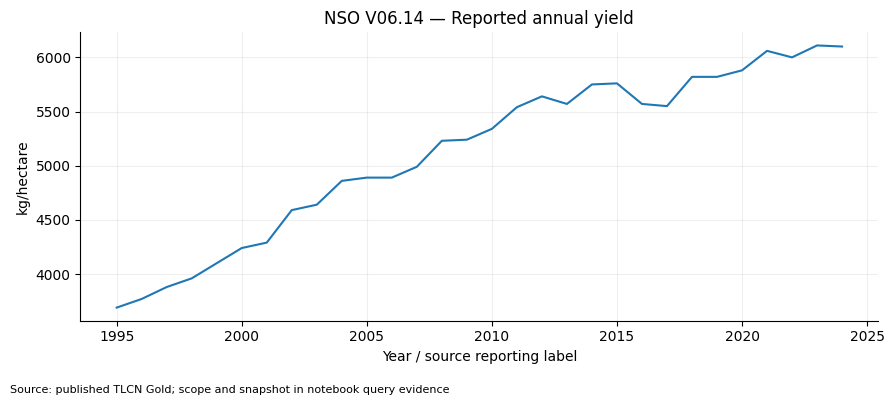

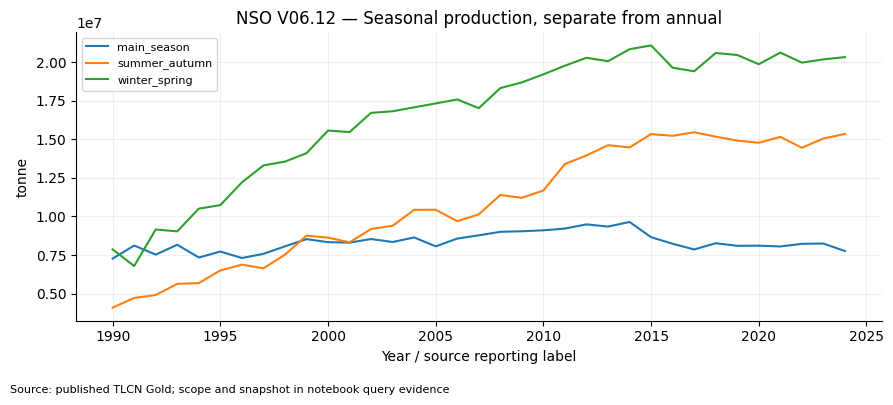

In [11]:
annual_plot(yr,'value','NSO V06.14 — Reported annual yield','kg/hectare')
annual_plot(seasons,'value','NSO V06.12 — Seasonal production, separate from annual','tonne',group='season')

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** Không cộng annual vào seasonal. V06.14 là publication riêng; không chọn MAX/FIRST để giải quyết khác biệt giữa publications.

In [12]:
s=endpoint_change(yr)
findings.append(dict(id='VN03',title='Reported yield trong V06.14',observation=f"{s['first_value']:,.2f} → {s['last_value']:,.2f} kg/ha, {s['first_year']}–{s['last_year']} ({s['change_pct']:+.2f}%).",scope='V06.14.csv; national annual quantity',interpretation='Yield tăng/giảm là descriptive source observation; không đồng nhất với derived yield của V06.12.',query='nso_observations',cell='Câu hỏi 3',numbers=s))
latest=seasons[seasons.year_key==seasons.year_key.max()].sort_values('value',ascending=False)
winner=latest.iloc[0]
findings.append(dict(id='VN04',title='Season có reported production lớn nhất trong selected table',observation=f"Năm {int(winner.year_key)}, {winner.season}: {winner.value:,.2f} tonnes, trong {len(latest)} seasonal observations của V06.12.",scope='V06.12.csv; national seasonal quantity, no annual summation',interpretation='Đây là so sánh các season do nguồn định nghĩa, không xác nhận coverage của mọi lịch mùa vụ.',query='nso_observations',cell='Câu hỏi 3'))

## Câu hỏi 4 — Source-defined regional categories

In [13]:
regions=client.query('nso_observations',source_table='V06.15.csv',start_year=1995,end_year=2024,level='region')
regions=regions[(regions.measure=='production')&(regions.season=='annual')&(regions.statistic_kind=='quantity')].copy()
regions['value']=pd.to_numeric(regions.value);regions['source_label']=regions.source_labels_json.map(label)
latest_regions=regions[regions.year_key==regions.year_key.max()].copy()
display(regions.shape,latest_regions[['geography_key','source_label','value','unit','release_status']])

(180, 18)

,geography_key,source_label,value,unit,release_status
126,5e1a9a6d26d62fc8fda551a2fd2865108082fcd3c6b86f...,Bắc Trung Bộ và Duyên hải miền Trung | B?c Tru...,7304600.0,tonne,provisional
127,135ae72c78ca38da73bf615a7ccd836b2f72425866b2e0...,Tây Nguyên,1567100.0,tonne,provisional
128,93d7787494fa783621f71d22a9b67166ed01ea6d332f28...,Trung du và miền núi phía Bắc | Trung du và mi...,3259600.0,tonne,provisional
129,85b89bea86a26559a5229abdef510b6390195242fc71b4...,Đông Nam Bộ | Ðông Nam B?,1457000.0,tonne,provisional
130,7230c733abd9fd7321bf2f762c5ba1e5ebd166e6bd8925...,Đồng bằng sông Hồng | Ð?ng b?ng sông H?ng,5345900.0,tonne,provisional
131,7e0ae41318dc9d57f323dc586c7132f7a51e01a2223022...,Đồng bằng sông Cửu Long | Ð?ng b?ng sông C?u Long,24517400.0,tonne,provisional


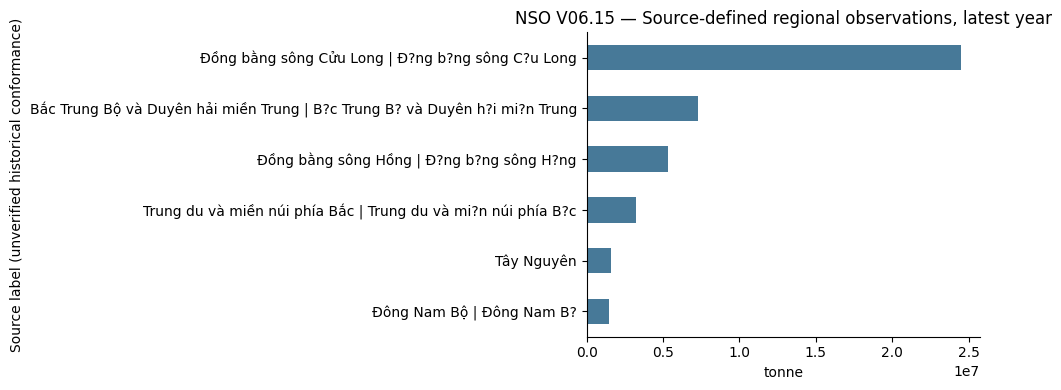

In [14]:
fig,ax=plt.subplots(figsize=(10,4));latest_regions.set_index('source_label').value.sort_values().plot.barh(ax=ax,color='#477998')
ax.set(title='NSO V06.15 — Source-defined regional observations, latest year',xlabel='tonne',ylabel='Source label (unverified historical conformance)');fig.tight_layout();plt.show();plt.close(fig)

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** Chỉ so sánh các observations được nguồn gọi là region, không SUM thành national total và không coi candidate labels là official historical geography.

## Key Findings

Measured batch `ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235`.

### VN01 — Thay đổi annual production_t

**OBSERVATION:** V06.12: 19,225,100.00 năm 1990 → 43,451,600.00 năm 2024 (+126.01%).

**Scope:** NSO V06.12.csv, national, annual, quantity; unit in metric

**INTERPRETATION / LIMITATION:** So sánh endpoints trong đúng publication; không suy causal attribution hoặc release vintage.

**Reproduce:** query `nso_observations`, Câu hỏi 1.

### VN02 — Thay đổi annual area_ha

**OBSERVATION:** V06.12: 6,042,800.00 năm 1990 → 7,127,100.00 năm 2024 (+17.94%).

**Scope:** NSO V06.12.csv, national, annual, quantity; unit in metric

**INTERPRETATION / LIMITATION:** So sánh endpoints trong đúng publication; không suy causal attribution hoặc release vintage.

**Reproduce:** query `nso_observations`, Câu hỏi 1.

### VN05 — Xu hướng dài hạn che giai đoạn sau observed peak

**OBSERVATION:** Annual production đạt observed peak 45,091,000.00 tonnes năm 2015; tới 2024 còn 43,451,600.00 tonnes (-3.64%). Diện tích cùng interval thay đổi -8.95%.

**Scope:** NSO V06.12.csv, national annual quantity; peak selected from observed 1990–2024 series

**INTERPRETATION / LIMITATION:** Descriptive peak-to-latest comparison; không phải formal structural-break test hoặc chứng minh area gây thay đổi production.

**Reproduce:** query `nso_observations`, Câu hỏi 1.

### VN03 — Reported yield trong V06.14

**OBSERVATION:** 3,690.00 → 6,100.00 kg/ha, 1995–2024 (+65.31%).

**Scope:** V06.14.csv; national annual quantity

**INTERPRETATION / LIMITATION:** Yield tăng/giảm là descriptive source observation; không đồng nhất với derived yield của V06.12.

**Reproduce:** query `nso_observations`, Câu hỏi 3.

### VN04 — Season có reported production lớn nhất trong selected table

**OBSERVATION:** Năm 2024, winter_spring: 20,333,900.00 tonnes, trong 3 seasonal observations của V06.12.

**Scope:** V06.12.csv; national seasonal quantity, no annual summation

**INTERPRETATION / LIMITATION:** Đây là so sánh các season do nguồn định nghĩa, không xác nhận coverage của mọi lịch mùa vụ.

**Reproduce:** query `nso_observations`, Câu hỏi 3.

## Limitations

Provisional/unconfirmed không phải FINAL. V06.12/V06.14/V06.15 không được merge publication identity. Development index % tách khỏi quantity. Không official province/region mappings hoặc causal proof.

In [15]:
print(save_evidence(ROOT, '01_vietnam_rice_production', client, findings))
print('Query audit:')
display(pd.DataFrame(client.evidence)[['query','row_count','query_seconds','response_bytes','batch']])

docs/analytics/evidence/01_vietnam_rice_production.json
Query audit:


,query,row_count,query_seconds,response_bytes,batch
0,publication,17,0.000000,4333,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
1,nso_observations,560,0.399633,216176,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
2,nso_observations,30,0.294546,29037,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
3,nso_observations,180,0.199074,129434,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
